# Grafo de colaboración de Samuel L. Jackson
**Análisis y Ciencia de Datos — UNIS · Parte individual · Rodolfo Flores**

Sea $B$ la matriz actores × películas ($B_{am}=1$ si el actor $a$ sale en la película $m$). Entonces $A=BB^\top$
cuenta cuántas películas comparten dos actores: un grafo de colaboración es un **kernel**, igual que el del bosque
de la parte grupal (dos filas se parecen si caen en las mismas hojas).

El notebook corre de principio a fin **sin API key** usando el cache de `cache/`. Para reconstruir el cache hace falta
definir `TMDB_API_KEY` en el entorno (nunca se guarda en el repositorio).

In [1]:
from collections import Counter, defaultdict, deque
from itertools import combinations

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans

from grafo import Graph
from tmdb_utils import TMDBAPIUtils

pd.set_option("display.width", 140)
np.set_printoptions(precision=4, suppress=True)

## I.1 Cuenta y API key
Cuenta creada en themoviedb.org con API key de *developer*. La key se lee de la variable de entorno `TMDB_API_KEY`;
`.env` está en `.gitignore`.

## I.2 Clase `Graph`
Implementada en `grafo.py`: nodos `(id, nombre)`, aristas no dirigidas guardadas con la clave `(min, max)` para que
$(a,b)$ y $(b,a)$ sean la misma, y el peso sube en 1 cada vez que se agrega una arista que ya existe.

In [2]:
g_prueba = Graph()
for nodo in [(1, "a"), (2, "b"), (3, "c"), (1, "repetido")]:
    g_prueba.add_node(nodo)
g_prueba.add_edge(1, 2); g_prueba.add_edge(2, 1); g_prueba.add_edge(2, 3)
A_prueba, ids_prueba = g_prueba.adjacency()
print("nodos:", g_prueba.total_nodes(), "| aristas:", g_prueba.total_edges(), "| grado máximo:", g_prueba.max_degree_nodes())
print("orden de filas:", ids_prueba); print(A_prueba)
assert g_prueba.nodes[1] == "a" and A_prueba[0, 1] == 2 and (A_prueba == A_prueba.T).all()

nodos: 3 | aristas: 2 | grado máximo: {2: 2}
orden de filas: [1, 2, 3]
[[0. 2. 0.]
 [2. 0. 1.]
 [0. 1. 0.]]


## I.3 Clase `TMDBAPIUtils`
En `tmdb_utils.py`. Cada respuesta del API se guarda como JSON en `cache/` y se lee de ahí si ya existe.
* `get_movie_cast(movie_id, limit, exclude_ids)`: miembros del elenco con `order` entre 0 y `limit − 1`, sin `exclude_ids`.
* `get_movie_credits_for_person(person_id, start_date, end_date)`: `id`, `title`, `release_date` y `order` de cada
  película; filtramos por fecha nosotros, quitamos documentales (`genre_ids` contiene 99) y papeles donde la persona
  se interpreta a sí misma (personaje "Himself", "Herself" o "Self").

In [3]:
api = TMDBAPIUtils(cache_dir="cache")
SEMILLA_NOMBRE = "Samuel L. Jackson"
candidatos = api.buscar_persona(SEMILLA_NOMBRE)
SEMILLA = candidatos[0]["id"]
print("semilla:", candidatos[0]["name"], "| id TMDB:", SEMILLA, "| conocido por:", candidatos[0].get("known_for_department"))

semilla: Samuel L. Jackson | id TMDB: 2231 | conocido por: Acting


## I.4 Construcción del grafo
`limit = 5` y ventana del 1 de enero de 1975 al 31 de diciembre de 2025. Una película **cuenta** para un actor si salió
dentro de la ventana y el actor aparece con `order < 5`.

In [4]:
LIMIT = 5
INICIO, FIN = "1975-01-01", "2025-12-31"


def peliculas_que_cuentan(persona):
    return {c["id"]: c for c in api.get_movie_credits_for_person(persona, INICIO, FIN)
            if c["order"] is not None and c["order"] < LIMIT}


g = Graph()
# (a) la semilla
g.add_node((SEMILLA, SEMILLA_NOMBRE))
# (b) elenco principal de cada película que cuenta para la semilla
pelis_semilla = peliculas_que_cuentan(SEMILLA)
for pid in pelis_semilla:
    for miembro in api.get_movie_cast(pid, LIMIT, exclude_ids=[SEMILLA]):
        g.add_node((miembro["id"], miembro["name"]))
print(f"películas que cuentan para la semilla: {len(pelis_semilla)} | nodos tras (b): {g.total_nodes()}")

# (c) una arista por película y por pareja, entre nodos que ya están en el grafo
cuenta_para = {n: peliculas_que_cuentan(n) for n in g.nodes}
titulo = {}
nodos_por_peli = defaultdict(set)
for n, pelis in cuenta_para.items():
    for pid, c in pelis.items():
        nodos_por_peli[pid].add(n)
        titulo[pid] = f"{c['title']} ({c['release_date'][:4]})"
for pid, nodos in nodos_por_peli.items():
    for a, b in combinations(sorted(nodos), 2):
        g.add_edge(a, b)

A, ids = g.adjacency()
nombre = [g.nodes[i] for i in ids]
grado = g.degree()
print("nodos:", g.total_nodes(), "| aristas:", g.total_edges(), "| peso total:", int(A.sum() / 2))
print("nodo(s) de mayor grado:", {g.nodes[n]: d for n, d in g.max_degree_nodes().items()})
print("llamadas nuevas al API en esta corrida:", api.llamadas_api)

películas que cuentan para la semilla: 108 | nodos tras (b): 377
nodos: 377 | aristas: 2666 | peso total: 2984
nodo(s) de mayor grado: {'Samuel L. Jackson': 371}
llamadas nuevas al API en esta corrida: 0


In [5]:
top_grado = sorted(grado.items(), key=lambda t: -t[1])[:10]
pd.DataFrame([(g.nodes[n], d, int(A[ids.index(n)].sum())) for n, d in top_grado],
             columns=["actor", "grado", "grado ponderado"])

,actor,grado,grado ponderado
0,Samuel L. Jackson,371,415
1,Bruce Willis,54,71
2,Robert De Niro,45,56
3,Nicolas Cage,44,59
4,Julianne Moore,43,47
5,Danny Glover,42,48
6,Morgan Freeman,41,50
7,Ed Harris,39,42
8,Gary Oldman,39,45
9,Kevin Spacey,36,38


In [6]:
aristas_pesadas = sorted(g.edges.items(), key=lambda t: -t[1])[:10]
pd.DataFrame([(g.nodes[a], g.nodes[b], w) for (a, b), w in aristas_pesadas],
             columns=["actor 1", "actor 2", "películas juntos"])

,actor 1,actor 2,películas juntos
0,Vin Diesel,Michelle Rodriguez,8
1,Eddie Murphy,Antonio Banderas,8
2,Scarlett Johansson,Chris Evans,7
3,Bruce Willis,Samuel L. Jackson,5
4,Antonio Banderas,Salma Hayek Pinault,5
5,Chris Rock,Jada Pinkett Smith,5
6,Rupert Everett,Colin Firth,5
7,Natalie Portman,Ewan McGregor,4
8,Samuel L. Jackson,Hayden Christensen,4
9,Mark Strong,Colin Firth,4


**Resultado.** 108 películas cuentan para Samuel L. Jackson; con sus elencos principales el grafo tiene **377 actores y
2 666 aristas**. El nodo de mayor grado es la propia semilla (371 vecinos), lejos del segundo, Bruce Willis (54).
Las aristas más pesadas no involucran a la semilla: el paso (c) suma **todas** las películas que comparten dos actores
del grafo en la ventana, así que aparecen parejas de franquicias (Vin Diesel–Michelle Rodriguez en *Fast & Furious*,
Eddie Murphy–Antonio Banderas en *Shrek*, Chris Evans–Scarlett Johansson en Marvel).

## I.5 Visualización

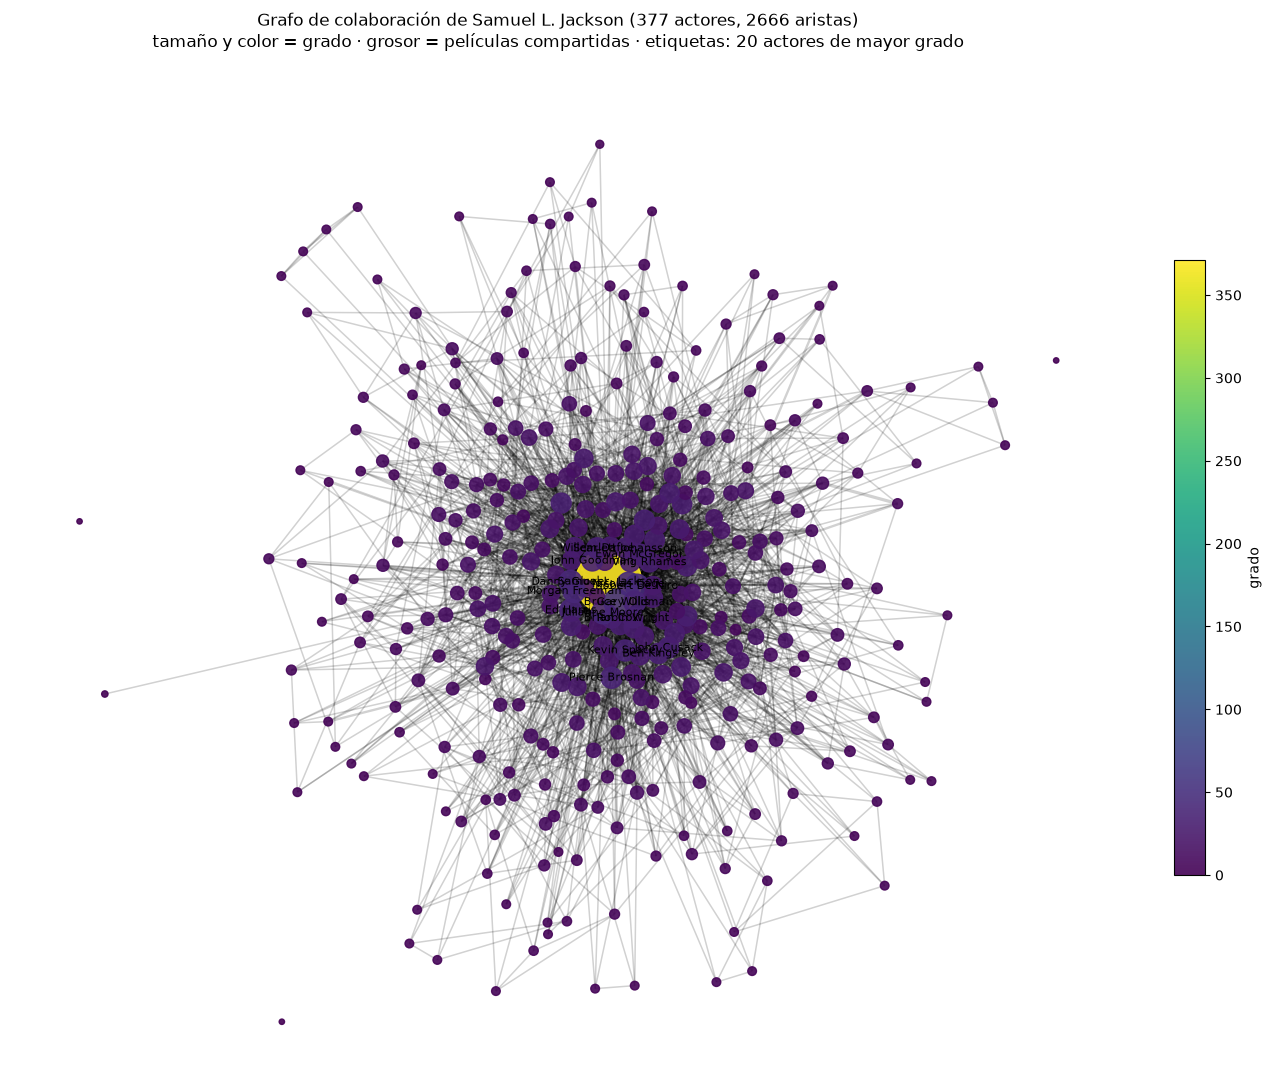

In [7]:
G = nx.Graph()
G.add_nodes_from(ids)
G.add_weighted_edges_from([(a, b, w) for (a, b), w in g.edges.items()])
pos = nx.spring_layout(G, weight="weight", seed=7, k=0.35)
tam = np.array([grado[n] for n in G.nodes])
fig, ax = plt.subplots(figsize=(14, 11))
nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.18, width=[0.5 + 0.6 * G[a][b]["weight"] for a, b in G.edges])
nc = nx.draw_networkx_nodes(G, pos, ax=ax, node_size=15 + 6 * tam, node_color=tam, cmap="viridis", alpha=0.9)
etiquetas = {n: g.nodes[n] for n, _ in sorted(grado.items(), key=lambda t: -t[1])[:20]}
nx.draw_networkx_labels(G, pos, etiquetas, font_size=8, ax=ax)
fig.colorbar(nc, ax=ax, shrink=0.6, label="grado")
ax.set_title(f"Grafo de colaboración de {SEMILLA_NOMBRE} ({g.total_nodes()} actores, {g.total_edges()} aristas)\n"
             "tamaño y color = grado · grosor = películas compartidas · etiquetas: 20 actores de mayor grado")
ax.axis("off"); fig.tight_layout(); fig.savefig("figuras/grafo.png", dpi=160); plt.show()

## I.6 El espectro
$L=D-A$ y $L_{sym}=I-D^{-1/2}AD^{-1/2}$ con $D$ la diagonal de grados **ponderados**. Todo con `numpy`;
`networkx` solo para verificar.

In [8]:
def laplacianos(A, convencion="aislado_cero"):
    """L = D - A y L_sym = I - D^{-1/2} A D^{-1/2}.

    Un nodo aislado tiene d = 0 y D^{-1/2} no existe. Con D^{-1/2}_ii := 0 la fila de L_sym queda e_i
    (valor propio 1). Con la convención "aislado_cero" escribimos L_sym = D^{-1/2} L D^{-1/2} (que es lo mismo
    cuando d > 0) y la fila del aislado queda en cero: valor propio 0, como cualquier componente."""
    d = A.sum(axis=1)
    L = np.diag(d) - A
    d_inv_sqrt = np.zeros_like(d)
    d_inv_sqrt[d > 0] = 1 / np.sqrt(d[d > 0])
    L_sym = np.eye(len(d)) - d_inv_sqrt[:, None] * A * d_inv_sqrt[None, :]
    if convencion == "aislado_cero":
        L_sym[d == 0, d == 0] = 0.0
    return L, L_sym


def componentes_bfs(A):
    """Componentes conexas con una búsqueda en anchura propia."""
    n = len(A)
    vecinos = [np.flatnonzero(A[i]) for i in range(n)]
    etiqueta = -np.ones(n, dtype=int)
    c = 0
    for s in range(n):
        if etiqueta[s] >= 0:
            continue
        etiqueta[s] = c
        cola = deque([s])
        while cola:
            u = cola.popleft()
            for v in vecinos[u]:
                if etiqueta[v] < 0:
                    etiqueta[v] = c
                    cola.append(v)
        c += 1
    return c, etiqueta


i_sem = ids.index(SEMILLA)
sin = [i for i in range(len(ids)) if i != i_sem]
A_sin = A[np.ix_(sin, sin)]
ids_sin = [ids[i] for i in sin]

### (a) Componentes

In [9]:
filas = []
for etiqueta_g, M in [("con semilla", A), ("sin semilla", A_sin)]:
    n_bfs, _ = componentes_bfs(M)
    aislados = int((M.sum(1) == 0).sum())
    vals_ingenua = np.linalg.eigvalsh(laplacianos(M, "ingenua")[1])
    vals = np.linalg.eigvalsh(laplacianos(M)[1])
    filas.append({"grafo": etiqueta_g, "nodos": len(M), "aislados": aislados, "componentes (BFS)": n_bfs,
                  "λ<1e-8, D^-1/2=0 ingenuo": int((vals_ingenua < 1e-8).sum()),
                  "λ<1e-8, convención corregida": int((vals < 1e-8).sum()),
                  "networkx (verificación)": nx.number_connected_components(nx.from_numpy_array(M))})
pd.DataFrame(filas).set_index("grafo")

,nodos,aislados,componentes (BFS),"λ<1e-8, D^-1/2=0 ingenuo","λ<1e-8, convención corregida",networkx (verificación)
grafo,,,,,,
con semilla,377,3,4,1,4,4
sin semilla,376,3,5,2,5,5


**En nuestros datos.** Con la semilla hay **4 componentes**: la principal y **3 actores aislados** (Kendrick Lamar,
Serena Williams y Mustard). Salen en el elenco principal de una película de Jackson, pero en sus propios créditos ese
papel es *Himself/Herself*, así que la película no cuenta para ellos y el paso (c) no les da ninguna arista. Sin la semilla
hay 5: la principal (369), los 3 aislados y un grupo de 4 actores italianos de *The Red Violin* que solo se conectaban
con el resto a través de Jackson. Con la convención ingenua el conteo da 1 y 2: se pierden exactamente los 3 aislados.

**Nodos aislados.** Sin la semilla quedan actores que solo estaban conectados a ella: grado 0 y $D^{-1/2}_{ii}=1/0$.
Si ponemos un cero en esa entrada, $(D^{-1/2}AD^{-1/2})$ tiene fila y columna $i$ en cero y $L_{sym}$ conserva el 1 de la
identidad: ese nodo aporta un valor propio **1**, no 0, y el conteo de valores propios nulos se queda corto exactamente por
el número de aislados. Nuestra convención: definir $L_{sym}=D^{-1/2}LD^{-1/2}$ con $D^{-1/2}_{ii}:=0$ para los aislados
(es idéntica a $I-D^{-1/2}AD^{-1/2}$ cuando $d_i>0$). La fila del aislado queda en cero, su valor propio es 0 y el conteo
vuelve a cuadrar con BFS: un nodo aislado **es** una componente.

### (b) Brecha espectral

λ2 con semilla = 0.000000 | λ2 sin semilla = -0.000000
networkx (verificación) λ2 con semilla: 0.0


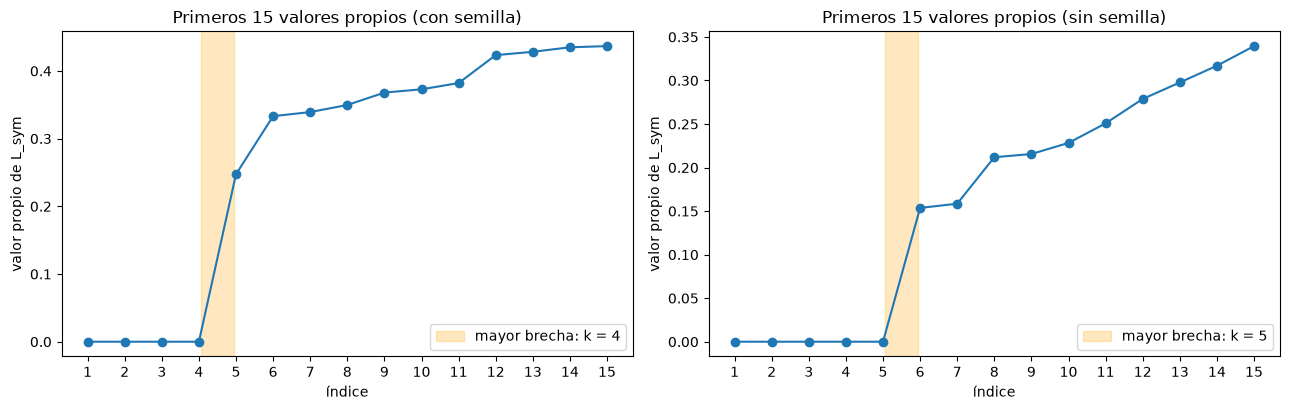

brechas con semilla: [0.     0.     0.     0.2474 0.0858 0.0061 0.0105 0.0183 0.0048 0.0093
 0.0413 0.0049 0.0067 0.0017]
k con semilla: 4 | k sin semilla: 5


In [10]:
vals_con, vecs_con = np.linalg.eigh(laplacianos(A)[1])
vals_sin, vecs_sin = np.linalg.eigh(laplacianos(A_sin)[1])
print(f"λ2 con semilla = {vals_con[1]:.6f} | λ2 sin semilla = {vals_sin[1]:.6f}")
print("networkx (verificación) λ2 con semilla:",
      round(float(np.sort(np.linalg.eigvalsh(nx.normalized_laplacian_matrix(G, nodelist=ids).toarray()))[1]), 6))


def brecha(vals, m=15):
    """k con la mayor brecha λ_{k+1} − λ_k entre los primeros m valores propios."""
    gaps = np.diff(vals[:m])
    return int(np.argmax(gaps)) + 1, gaps


k_con, gaps_con = brecha(vals_con)
k_sin, gaps_sin = brecha(vals_sin)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for a, v, k, t in [(ax[0], vals_con, k_con, "con semilla"), (ax[1], vals_sin, k_sin, "sin semilla")]:
    a.plot(range(1, 16), v[:15], "o-")
    a.axvspan(k + 0.05, k + 0.95, color="orange", alpha=0.25, label=f"mayor brecha: k = {k}")
    a.set_xlabel("índice"); a.set_ylabel("valor propio de L_sym"); a.set_title(f"Primeros 15 valores propios ({t})")
    a.set_xticks(range(1, 16)); a.legend()
fig.tight_layout(); fig.savefig("figuras/espectro.png", dpi=150); plt.show()
print("brechas con semilla:", np.round(gaps_con, 4))
print("k con semilla:", k_con, "| k sin semilla:", k_sin)

**Brecha.** Con la semilla, $\lambda_2 = 0$ porque el grafo **no** es conexo (los 3 aislados); los primeros cuatro valores
propios son cero y la mayor brecha está en $k=4$. Sin la semilla hay cinco ceros. En teoría el grafo con semilla siempre
es conexo, porque en (b) todo actor entra por compartir una película con ella; aquí falla solo por la regla de excluir
los papeles de sí mismo. En la componente de la semilla, $\lambda_2 = 0.247$.

**¿Por qué la brecha puede delatar comunidades aunque el grafo sea conexo?** La semilla es un *hub* que toca a casi todos
con aristas de peso 1 o 2. En $L_{sym}$ cada arista se divide entre $\sqrt{d_i d_j}$ y el grado de la semilla es enorme
(415), así que sus aristas pesan poco. Los grupos que están muy conectados entre sí y solo se unen al resto a través
de la semilla producen valores propios pequeños, casi como si fueran componentes separadas, y la brecha los cuenta.

### (c) Clustering espectral (con la semilla)
Ng–Jordan–Weiss: los $k$ vectores propios de los valores propios más pequeños, cada fila normalizada a norma 1, y $k$-means.

In [11]:
# Los nodos aislados aparecen como componentes propias (valores propios 0) y la brecha los "detecta" como
# comunidades de un solo actor. Aplicamos el método a la componente que contiene a la semilla.
_, etq_con = componentes_bfs(A)
comp_sem = np.flatnonzero(etq_con == etq_con[i_sem])
print("fuera de la componente de la semilla:", [nombre[i] for i in range(len(ids)) if etq_con[i] != etq_con[i_sem]])
vals_s, vecs_s = np.linalg.eigh(laplacianos(A[np.ix_(comp_sem, comp_sem)])[1])
k_s, gaps_s = brecha(vals_s)
print(f"componente de la semilla: {len(comp_sem)} actores | λ2 = {vals_s[1]:.4f}")
print("brechas:", np.round(gaps_s, 4), "-> mayor brecha en k =", k_s)
K = k_s if k_s >= 2 else int(np.argmax(gaps_s[1:])) + 2
print("k usado (mayor brecha con k ≥ 2):", K)


def clustering_espectral(K, semilla_km=0):
    U = vecs_s[:, :K]
    U = U / np.linalg.norm(U, axis=1, keepdims=True)
    etiquetas = KMeans(n_clusters=K, n_init=50, random_state=semilla_km).fit_predict(U)
    filas = []
    for c in range(K):
        miembros = [ids[comp_sem[i]] for i in np.flatnonzero(etiquetas == c)]
        top_actores = sorted(miembros, key=lambda n: -grado[n])[:3]
        pelis = Counter(pid for n in miembros for pid in cuenta_para[n])
        filas.append({"comunidad": c, "tamaño": len(miembros),
                      "actores de mayor grado": ", ".join(g.nodes[n] for n in top_actores),
                      "películas más repetidas (miembros)": " · ".join(f"{titulo[p]} ×{v}" for p, v in pelis.most_common(3))})
    return etiquetas, pd.DataFrame(filas).set_index("comunidad").sort_values("tamaño", ascending=False)


pd.set_option("display.max_colwidth", 120)
etiquetas_K, tabla_com = clustering_espectral(K)
tabla_com

fuera de la componente de la semilla: ['Kendrick Lamar', 'Serena Williams', 'Mustard']
componente de la semilla: 374 actores | λ2 = 0.2474
brechas: [0.2474 0.0858 0.0061 0.0105 0.0183 0.0048 0.0093 0.0413 0.0049 0.0067
 0.0017 0.0095 0.0112 0.0085] -> mayor brecha en k = 1
k usado (mayor brecha con k ≥ 2): 2


,tamaño,actores de mayor grado,películas más repetidas (miembros)
comunidad,,,
0,370,"Samuel L. Jackson, Bruce Willis, Robert De Niro",Jackie Brown (1997) ×5 · Snakes on a Plane (2006) ×5 · Shaft (2000) ×5
1,4,"Carlo Cecchi, Irene Grazioli, Anita Laurenzi",The Red Violin (1998) ×4 · The Escort (1993) ×1 · An Impossible Crime (2001) ×1


In [12]:
# la brecha λ2→λ3 es pequeña; con k = 3 la partición se vuelve más fácil de leer
etiquetas_3, tabla_3 = clustering_espectral(3)
tabla_3

,tamaño,actores de mayor grado,películas más repetidas (miembros)
comunidad,,,
0,187,"Robert De Niro, Nicolas Cage, Julianne Moore",Spider-Man: Homecoming (2017) ×4 · Snakes on a Plane (2006) ×4 · Hero (1992) ×4
1,115,"Samuel L. Jackson, Bruce Willis, Danny Glover",Pulp Fiction (1994) ×5 · The Great White Hype (1996) ×5 · Against the Wall (1994) ×5
2,72,"Wesley Snipes, Giancarlo Esposito, Lynn Whitfield",Coach Carter (2005) ×4 · Menace II Society (1993) ×4 · Fresh (1994) ×4


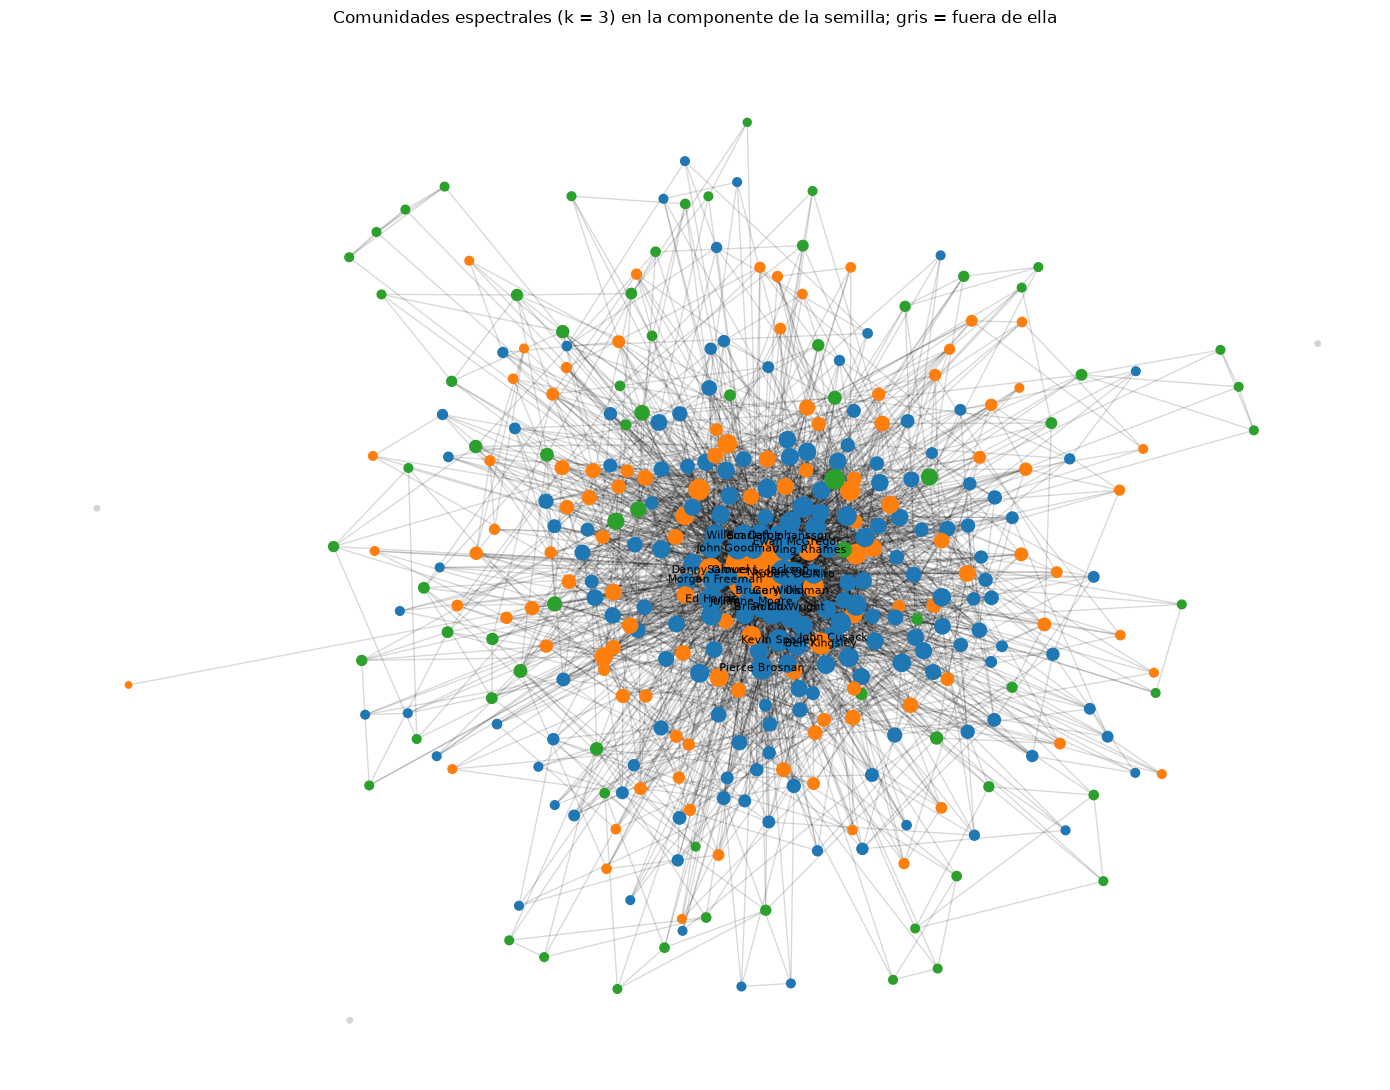

In [13]:
comunidad = -np.ones(len(ids), dtype=int)
comunidad[comp_sem] = etiquetas_3
color = {n: comunidad[i] for i, n in enumerate(ids)}
fig, ax = plt.subplots(figsize=(14, 11))
nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.15)
paleta = ["tab:blue", "tab:orange", "tab:green"]
nx.draw_networkx_nodes(G, pos, ax=ax, node_size=15 + 6 * tam,
                       node_color=[paleta[color[n]] if color[n] >= 0 else "lightgrey" for n in G.nodes])
nx.draw_networkx_labels(G, pos, etiquetas, font_size=8, ax=ax)
ax.set_title("Comunidades espectrales (k = 3) en la componente de la semilla; gris = fuera de ella"); ax.axis("off")
fig.tight_layout(); fig.savefig("figuras/comunidades.png", dpi=160); plt.show()

**¿Corresponden a algo real?** Sí.
* Con $k=2$ (la mayor brecha después de $k=1$) se separan **4 actores italianos** de *The Red Violin* (1998, coproducción
  ítalo-canadiense): un **país**, unido al resto solo a través de Jackson.
* Con $k=3$ aparecen tres épocas e industrias reconocibles: el **Hollywood comercial** de los 2000–2010 (De Niro, Cage,
  Julianne Moore; *Spider-Man: Homecoming*, *Snakes on a Plane*); el **núcleo de Jackson de los 90** (Bruce Willis,
  Danny Glover; *Pulp Fiction*, *The Great White Hype*); y el **cine afroamericano de los 90 y 2000** (Wesley Snipes,
  Giancarlo Esposito, Lynn Whitfield; *Menace II Society*, *Fresh*, *Coach Carter*).

### (d) Vector de Fiedler (sin la semilla, componente más grande)

In [14]:
n_c, etq = componentes_bfs(A_sin)
mayor = np.argmax(np.bincount(etq))
idx = np.flatnonzero(etq == mayor)
A_cc = A_sin[np.ix_(idx, idx)]
ids_cc = [ids_sin[i] for i in idx]
v_cc, V_cc = np.linalg.eigh(laplacianos(A_cc)[1])
fiedler = V_cc[:, 1]
lado = fiedler >= 0
cruzan = [(a, b, A_cc[a, b]) for a in range(len(idx)) for b in range(a + 1, len(idx)) if A_cc[a, b] > 0 and lado[a] != lado[b]]
print(f"componente más grande sin la semilla: {len(idx)} de {len(ids_sin)} actores | λ2 = {v_cc[1]:.5f}")
print(f"lado + : {lado.sum()} actores | lado − : {(~lado).sum()} actores")
print(f"aristas que cruzan: {len(cruzan)} (peso {sum(w for *_, w in cruzan):.0f}) de {int((A_cc > 0).sum() / 2)}")


def describir(mascara):
    miembros = [ids_cc[i] for i in np.flatnonzero(mascara)]
    pelis = Counter(pid for n in miembros for pid in cuenta_para[n])
    return (sorted(miembros, key=lambda n: -grado[n])[:6], pelis.most_common(6))


for etiqueta_l, m in [("+", lado), ("−", ~lado)]:
    act, pel = describir(m)
    print(f"\nlado {etiqueta_l}: ", ", ".join(g.nodes[n] for n in act))
    print("   películas:", " · ".join(f"{titulo[p]} ×{v}" for p, v in pel))
print("\naristas que cruzan:")
for a, b, w in sorted(cruzan, key=lambda t: -t[2])[:15]:
    print(f"   {g.nodes[ids_cc[a]]} — {g.nodes[ids_cc[b]]} (peso {w:.0f})")

componente más grande sin la semilla: 369 de 376 actores | λ2 = 0.15364
lado + : 318 actores | lado − : 51 actores
aristas que cruzan: 344 (peso 377) de 2289

lado +:  Bruce Willis, Robert De Niro, Nicolas Cage, Julianne Moore, Morgan Freeman, Ed Harris
   películas: Lucky Number Slevin (2006) ×5 · Spider-Man: Homecoming (2017) ×4 · The Protégé (2021) ×4 · Snakes on a Plane (2006) ×4 · Hero (1992) ×4 · Changing Lanes (2002) ×4

lado −:  Danny Glover, Ving Rhames, Wesley Snipes, Angela Bassett, Ron Perlman, Liev Schreiber
   películas: Fresh (1994) ×4 · Chi-Raq (2015) ×4 · Spike & Co.: Do It a Cappella (1990) ×4 · Monkeybone (2001) ×3 · Kiss of Death (1995) ×3 · The Waterdance (1992) ×3

aristas que cruzan:
   Eddie Murphy — Antonio Banderas (peso 8)
   Jada Pinkett Smith — Chris Rock (peso 5)
   Bridget Fonda — John Cusack (peso 2)
   Sharon Stone — Peter Coyote (peso 2)
   Sharon Stone — Liev Schreiber (peso 2)
   Liev Schreiber — Ben Affleck (peso 2)
   Liev Schreiber — Naomi Watts (

**¿Qué separa el corte?** Sin la semilla, el vector de Fiedler de la componente grande (369 actores) separa **318** actores
del Hollywood comercial (Willis, De Niro, Cage, Moore, Freeman) de **51** del cine afroamericano e independiente (Danny Glover,
Ving Rhames, Wesley Snipes, Angela Bassett; *Fresh*, *Chi-Raq*, Spike Lee). Solo **344 de 2 289 aristas (15 %)** cruzan, y las
más pesadas son colaboraciones puntuales entre los dos mundos (Murphy–Banderas en *Shrek*, Jada Pinkett Smith–Chris Rock).

### (e) Centralidad: grado contra vector propio

In [15]:
w_A, V_A = np.linalg.eigh(A)
principal = np.abs(V_A[:, np.argmax(np.abs(w_A))])
cent = dict(zip(ids, principal / principal.max()))
# networkx no acepta grafos disconexos aquí: verificamos en la componente principal, donde vive el vector propio
cc = max(nx.connected_components(G), key=len)
nx_cent = nx.eigenvector_centrality_numpy(G.subgraph(cc), weight="weight")
print("verificación networkx (componente principal): max |dif| (normalizado) =",
      max(abs(cent[n] - nx_cent[n] / max(nx_cent.values())) for n in cc))
top5_grado = sorted(ids, key=lambda n: -grado[n])[:5]
top5_cent = sorted(ids, key=lambda n: -cent[n])[:5]
pd.DataFrame({"5 de mayor grado": [f"{g.nodes[n]} ({grado[n]})" for n in top5_grado],
              "5 de mayor centralidad de vector propio": [f"{g.nodes[n]} ({cent[n]:.3f})" for n in top5_cent]})

verificación networkx (componente principal): max |dif| (normalizado) = 6.938893903907228e-16


,5 de mayor grado,5 de mayor centralidad de vector propio
0,Samuel L. Jackson (371),Samuel L. Jackson (1.000)
1,Bruce Willis (54),Bruce Willis (0.372)
2,Robert De Niro (45),Nicolas Cage (0.255)
3,Nicolas Cage (44),John Travolta (0.229)
4,Julianne Moore (43),Morgan Freeman (0.223)


**¿Son los mismos?** No del todo: comparten 3 de 5 (Jackson, Willis, Cage). El **grado** cuenta con cuántos actores
distintos colaboró cada uno: mide alcance directo (De Niro y Julianne Moore tienen muchos coprotagonistas). La **centralidad
de vector propio** resuelve $Av=\lambda_{max}v$: un actor es central si sus vecinos son centrales y si comparte **varias**
películas con ellos (los pesos cuentan). Por eso suben John Travolta y Morgan Freeman, que repiten con Jackson y con los
nodos de mayor grado, aunque tengan menos vecinos. La semilla domina ambas medidas porque todo el grafo se construyó a su alrededor.